# One Model on Split Data Using `consensus_sample`

Suppose an online shop wants to know what makes a visitor buy something, from a log of 200,000 visits. That is **one** model, a logistic regression, that should learn from **all** of the visits.

With a lot of data, sampling becomes slow. Every step of the sampler evaluates the model on every row. `pymc_ray.consensus_sample` speeds this up with [consensus Monte Carlo](https://doi.org/10.1080/17509974.2016.1155553):

1. The rows are split into *shards*, and each shard is sampled on its own [Ray](https://www.ray.io) worker, without talking to the others.

2. Each shard sees only part of the data, so its posterior (a *subposterior*) is wider than the full one. Each shard also gets a weakened prior, so that over all shards the prior counts once rather than once per shard. `consensus_sample` does this for you.

3. The shards' draws are combined, averaged draw by draw, weighted by how precise each shard is. This is exact when every subposterior is Gaussian, and close to exact when every shard has plenty of rows.

In this notebook we simulate some data, write the model, fit it with consensus, and check the result against an ordinary fit on all the data. Finally we check the model itself, with a posterior predictive check and LOO cross-validation, which also work shard by shard.

Warning
-------

Consensus is an approximation. It suits models like regressions, where every parameter is informed by every shard. Don't use it for hierarchical (multilevel) models, posteriors with multiple modes, or discrete parameters. Use `ShardedModel` instead, which is exact: see the [README](../README.md#exact-shardedmodel)

In [1]:
import os

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import ray

import pymc_ray as pmr

plt.rcParams.update(
    {
        "figure.figsize": (14, 4),
        "figure.dpi": 144,
        "figure.facecolor": "w",
        "axes.grid": True,
        "grid.linewidth": 0.5,
        "grid.linestyle": "--",
        "axes.spines.top": False,
        "axes.spines.bottom": False,
        "axes.spines.left": False,
        "axes.spines.right": False,
        "figure.constrained_layout.use": True,
    }
)

## Start Ray

`ray.init()` starts Ray on this machine and uses all of its CPUs. `log_to_driver=False` keeps the workers' logs out of the notebook.

To use a cluster instead, set the `RAY_ADDRESS` environment variable to the cluster's [Ray Client](https://docs.ray.io/en/latest/cluster/running-applications/job-submission/ray-client.html) address (for example `ray://localhost:10001`) before starting Jupyter. `runtime_env` then installs this notebook's PyMC version on the cluster and copies `pymc_ray` there.

In [2]:
ray_address = os.environ.get("RAY_ADDRESS")  # None: start Ray on this machine
runtime_env = {"pip": [f"pymc=={pm.__version__}", "narwhals>=2"], "py_modules": [pmr]} if ray_address else None
ray.init(address=ray_address, runtime_env=runtime_env, log_to_driver=False)
print(f"Ray is using {ray.cluster_resources()['CPU']:.0f} CPUs")

2026-10-28 08:17:11,341	INFO worker.py:1841 -- Started a local Ray instance.


Ray is using 14 CPUs


## Simulate some data

Each row is one visit with four features of the visit, and whether the visitor bought something. We choose the true effect of each feature ourselves, so we can check the estimates against them later. The effects are on the log-odds scale, so positive effects make a purchase more likely, negative ones less likely.

Shards are consecutive blocks of rows, so every shard should look like the data as a whole. Our rows are already in random order. If yours are sorted (by date, by store, etc.) shuffle them first.

In [3]:
rng = np.random.default_rng(0)
n_visits = 200_000
FEATURES = ["price", "discount", "returning", "time_on_site"]

true_intercept = -1.0
true_beta = pd.Series([-0.8, 0.5, 1.0, 0.3], index=FEATURES)

visits = pd.DataFrame(
    {
        "price": rng.normal(0, 1, n_visits),  # price relative to usual, standardized
        "discount": rng.integers(0, 2, n_visits),  # 1 if a discount was shown
        "returning": rng.integers(0, 2, n_visits),  # 1 for returning customers
        "time_on_site": rng.normal(0, 1, n_visits),  # standardized
    }
)
log_odds = true_intercept + visits[FEATURES].to_numpy() @ true_beta.to_numpy()
visits["bought"] = rng.binomial(1, 1 / (1 + np.exp(-log_odds)))
visits.head()

,price,discount,returning,time_on_site,bought
0,0.125730,1,0,-0.132435,1
1,-0.132105,0,0,2.207678,1
2,0.640423,0,1,-0.775874,0
3,0.104900,1,1,0.612219,1
4,-0.535669,1,1,-0.414033,1


## The model

`consensus_sample` needs a function that takes some data and returns a PyMC model.

The function is called once per shard, each time with different rows, so the model's parameters must not depend on which rows it receives. Here the parameters come from the fixed list `FEATURES`, not from the data.

In [4]:
def purchase_model(df: pd.DataFrame) -> pm.Model:
    """Logistic regression of `bought` on the features. Called once per shard."""
    with pm.Model(coords={"feature": FEATURES}) as model:
        # Priors
        intercept = pm.Normal("intercept", 0, 2)  # log-odds of buying when features are 0
        beta = pm.Normal("beta", 0, 1, dims="feature")  # effect of each feature
        # Likelihood
        log_odds = intercept + df[FEATURES].to_numpy() @ beta
        pm.Bernoulli("bought", logit_p=log_odds, observed=df["bought"].to_numpy())
    return model

Let's build the model once first, to check that it looks right:

In [5]:
purchase_model(visits)

## Fit with consensus

`consensus_sample` splits `visits` into `n_shards` shards and samples `purchase_model` on each of them in parallel. `sample_kwargs` are passed on to `pm.sample` on every shard.

In addition:

- `random_seed` makes the run reproducible.
- `return_subposteriors=True` also returns each shard's own fit, so that we can check them below.

Each shard should keep plenty of rows (here 25,000 each), so that its subposterior is close to Gaussian. `%%time` reports how long the cell took.

In [6]:
%%time
combined, shards = pmr.consensus_sample(
    purchase_model,
    visits,
    n_shards=8,
    sample_kwargs={"draws": 1000, "tune": 1000, "chains": 4},
    random_seed=42,
    return_subposteriors=True,
)

CPU times: user 220 ms, sys: 86.5 ms, total: 306 ms
Wall time: 48.5 s


## Look at the results

`combined` is a `DataTree` like the one `pm.sample` returns, with a `posterior` group that holds the combined draws. It has no sampler statistics, because no sampler produced these draws, so we show only the summary statistics.

In [7]:
az.summary(combined, kind="stats")

,mean,sd,eti89_lb,eti89_ub
intercept,-0.99,0.009,-1,-0.98
beta[price],-0.81,0.0056,-0.82,-0.8
beta[discount],0.51,0.01,0.49,0.52
beta[returning],0.99,0.01,0.97,1
beta[time_on_site],0.3,0.0051,0.29,0.31


## Check each shard

The combined draws can only be as good as the shards' draws, so check each shard's fit as you would any `pm.sample` result. Common rules of thumb: `r_hat` below 1.01, an effective sample size (`ess_bulk`) above 400, and no divergences.

In [8]:
shard_summary = pd.concat({i: az.summary(shard) for i, shard in enumerate(shards)}, names=["shard", "variable"])
shard_summary[(shard_summary["r_hat"] > 1.01) | (shard_summary["ess_bulk"] < 400)]

,,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
shard,variable,,,,,,,,,


In [9]:
[int(shard.sample_stats["diverging"].sum()) for shard in shards]

[0, 0, 0, 0, 0, 0, 0, 0]

## Compare with an exact fit

200,000 rows are still few enough to fit the usual way, with `pm.sample` on all the data, which gives the exact posterior. That lets us see how good the approximation is. With really large data this check is too slow, and the shard checks above are what you have.

In [10]:
%%time
exact = pm.sample(
    model=purchase_model(visits),
    draws=1000,
    tune=1000,
    chains=4,
    random_seed=42,
)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [intercept, beta]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 96 seconds.


CPU times: user 3.54 s, sys: 406 ms, total: 3.95 s
Wall time: 1min 36s


When you compare the two cells' wall times, keep in mind that consensus used 8 CPUs here (one per shard) and the exact fit 4 (one per chain). Consensus gains more as the data grow, because you can add shards, and machines, to keep each shard small.

The consensus and exact posteriors should have nearly the same means and standard deviations, and both should be close to the true values.

In [11]:
beta_exact = exact.posterior["beta"]
beta_consensus = combined.posterior["beta"]
pd.DataFrame(
    {
        "true": true_beta,
        "exact mean": beta_exact.mean(("chain", "draw")).to_series(),
        "consensus mean": beta_consensus.mean(("chain", "draw")).to_series(),
        "exact sd": beta_exact.std(("chain", "draw")).to_series(),
        "consensus sd": beta_consensus.std(("chain", "draw")).to_series(),
    }
).round(3)

,true,exact mean,consensus mean,exact sd,consensus sd
price,-0.8,-0.808,-0.808,0.006,0.006
discount,0.5,0.507,0.507,0.010,0.010
returning,1.0,0.988,0.988,0.010,0.010
time_on_site,0.3,0.298,0.297,0.005,0.005


The plot shows the idea behind consensus. Each thin line is one shard's posterior, it saw only an eighth of the data, so it is wide, and the shards disagree a little. The combination (thick blue) is much narrower, and it should lie on top of the exact posterior (dashed).

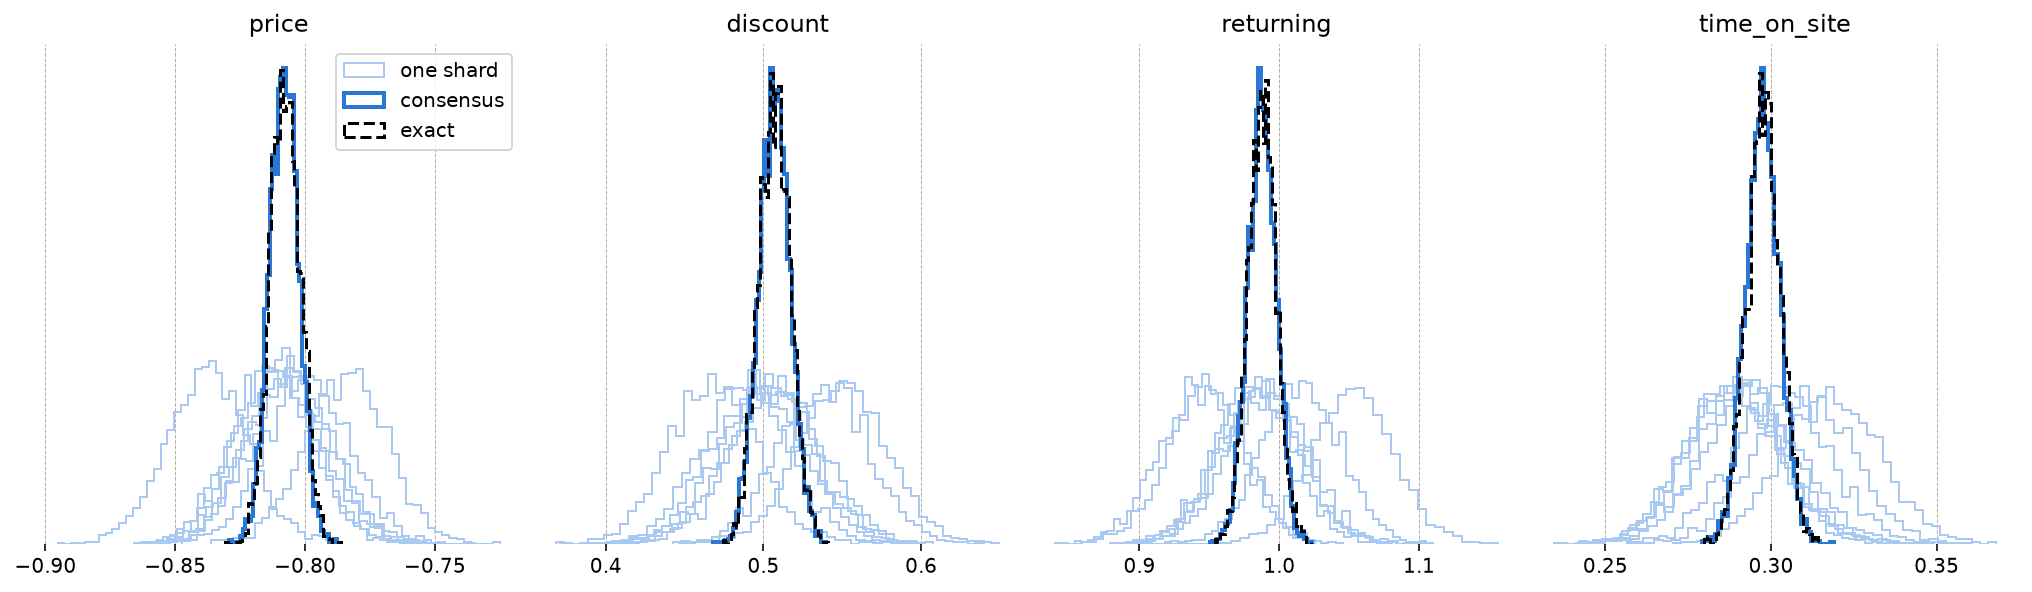

In [12]:
def draws(idata, feature):
    return idata.posterior["beta"].sel(feature=feature).to_numpy().ravel()


fig, axes = plt.subplots(1, len(FEATURES))
for ax, feature in zip(axes, FEATURES, strict=True):
    for i, shard in enumerate(shards):
        label = "one shard" if i == 0 else None
        ax.hist(
            draws(shard, feature),
            bins=40,
            density=True,
            histtype="step",
            color="#a9c9f0",
            label=label,
        )
    ax.hist(
        draws(combined, feature),
        bins=40,
        density=True,
        histtype="step",
        lw=2,
        color="#2a78d6",
        label="consensus",
    )
    ax.hist(
        draws(exact, feature),
        bins=40,
        density=True,
        histtype="step",
        lw=1.5,
        ls="--",
        color="black",
        label="exact",
    )
    ax.set(title=feature, yticks=[])
    ax.locator_params(axis="x", nbins=5)
axes[0].legend();

## Posterior predictive check

So far we checked that consensus finds the posterior. A posterior predictive check asks a different question, does the model describe the data? We simulate purchases from the fitted model and compare them with the real ones.

`pmr.sample_posterior_predictive` works like `pm.sample_posterior_predictive`, but shard by shard each Ray worker builds `purchase_model` on its own rows and simulates purchases for them, and the results are put back together in the original row order. In addition:

- `num_draws=100` uses 100 evenly spaced draws from each chain instead of all 1,000. The result holds one simulated purchase per row and draw, so 4 chains × 100 draws × 200,000
  rows = 80 million values, already 640 MB. Without `num_draws` it would be ten times as much.

- `extend_inferencedata=True` adds the simulated purchases (`posterior_predictive`) and the real ones (`observed_data`) to `combined`, as PyMC does.

`n_shards` only says how many pieces to split the work into, so it does not have to match the fit.

In [13]:
%%time
combined = pmr.sample_posterior_predictive(
    combined,
    purchase_model,
    visits,
    n_shards=8,
    num_draws=100,
    random_seed=42,
    extend_inferencedata=True,
)

CPU times: user 114 ms, sys: 101 ms, total: 215 ms
Wall time: 493 ms


For a yes/no outcome like `bought`, a calibration plot is a good check. The x-axis is the probability of buying that the model predicts for a visit. The y-axis is how often visits with that predicted probability actually ended in a purchase (the *conditional event probability*, CEP). If the model is well calibrated, the line follows the diagonal (of the visits predicted to buy with probability 0.3, about 30% did). The shaded band, narrow here because there are so many visits, shows how far the line may stray from the diagonal by chance alone, if the data came from the model itself.

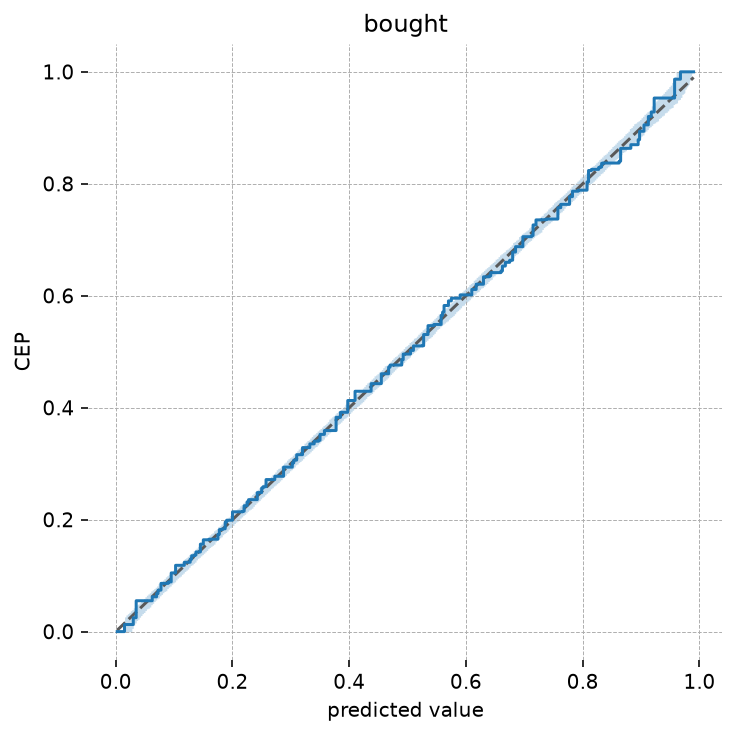

In [14]:
az.plot_ppc_pava(combined, figure_kwargs={"figsize": (5, 5)});

## LOO cross-validation

LOO estimates how well the model predicts a visit it has not seen. The estimate, `elpd_loo` (expected log pointwise predictive density), is mainly useful for comparing models.

It needs the log-likelihood of every row under every posterior draw, so 200,000 rows × 4,000 draws = 800 million values, 6.4 GB. `pmr.loo` never builds that table in one place. Each Ray worker computes it for its own rows only, runs PSIS-LOO on them, and sends back just one value per row. The result is the same as `az.loo` on the full table. As above, `n_shards` does not have to match the fit, more shards mean less memory per worker. With 32 shards each worker holds 6,250 rows × 4,000 draws, 200 MB.

In [15]:
%%time
loo_all = pmr.loo(combined, purchase_model, visits, n_shards=32)
loo_all

CPU times: user 88.1 ms, sys: 39.5 ms, total: 128 ms
Wall time: 12.7 s


Computed from 4000 posterior samples and 200000 observations log-likelihood matrix.

         Estimate       SE
elpd_loo -118164.32   182.66
p_loo        5.02        -
------

Pareto k diagnostic values:
                          Count   Pct.
(-Inf, 0.70]   (good)     200000  100.0%
   (0.70, 1]   (bad)           0    0.0%
    (1, Inf)   (very bad)      0    0.0%

Two things to check here. The Pareto *k* diagnostic should put every row in the "good" range, otherwise the estimate is unreliable for the rows outside it. And `p_loo`, the effective number of parameters, should be close to the 5 parameters of the model (`intercept` and four `beta`s). Much larger would point to a misspecified model.

LOO is computed from the combined draws, so it is only as good as the consensus approximation. Here we saw that it matches the exact fit.

### Compare models

Is it worth tracking `time_on_site`? We fit the model without it, with consensus again, and compute its LOO. In practice you would also check its shards, as above.

In [16]:
def purchase_model_no_time(df: pd.DataFrame) -> pm.Model:
    """`purchase_model` without the `time_on_site` feature."""
    features = ["price", "discount", "returning"]
    with pm.Model(coords={"feature": features}) as model:
        intercept = pm.Normal("intercept", 0, 2)
        beta = pm.Normal("beta", 0, 1, dims="feature")
        log_odds = intercept + df[features].to_numpy() @ beta
        pm.Bernoulli("bought", logit_p=log_odds, observed=df["bought"].to_numpy())
    return model

In [17]:
%%time
combined_no_time = pmr.consensus_sample(
    purchase_model_no_time,
    visits,
    n_shards=8,
    sample_kwargs={"draws": 1000, "tune": 1000, "chains": 4},
    random_seed=42,
)
loo_no_time = pmr.loo(combined_no_time, purchase_model_no_time, visits, n_shards=32)

CPU times: user 153 ms, sys: 87.4 ms, total: 240 ms
Wall time: 56.6 s


`pmr.loo` returns ArviZ's own LOO result, so `az.compare` takes it as it is. The best model comes first. `elpd_diff` is how much worse each model predicts than the best one, and `dse` is the standard error of that difference. A difference of many standard errors is clear evidence, and here dropping `time_on_site` makes the predictions clearly worse.

In [18]:
az.compare({"all features": loo_all, "without time_on_site": loo_no_time})

,rank,elpd_diff,dse,p_worse,diag_diff,diag_elpd,p,elpd,se,weight
all features,0,0.0,0.0,NaN,,,5.0,-118200.0,180.0,1.0
without time_on_site,1,-1800.0,59.0,1.0,,,4.0,-119900.0,180.0,0.0


## Additional Features Not Shown in This Tutorial

- **More data than fits in memory.** Pass a Ray Dataset, such as `ray.data.read_parquet(...)`, instead of a DataFrame. Each worker then loads only its own shard, and the full data never have to fit on this machine.

- **Too many predictive draws to hold in memory.** Pass `postprocess_fn` to `pmr.sample_posterior_predictive`. It runs on each worker with that shard's draws, so it can write them to storage, or reduce them to the statistics you need, and return only that.

- **Deterministics.** They are not included in `combined`: recompute them with `pm.compute_deterministics`.

In [19]:
ray.shutdown()